# Ji et al. 2020 — Cutaneous SCC · 01 Preprocessing

Malignant-cell load, per-sample thresholding, overdispersed-gene selection, PCA, Harmony integration on `sample`, UMAP, Leiden, and subtype annotation. Cutaneous squamous cell carcinoma (10x); malignant keratinocytes only.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
# custom 3CA dataloader
pth_3ca = os.path.join('..', '..', '..', '..', '..', '..', 'cancer', 'vertebrate', 'CCCA')
sys.path.append(pth_3ca)
from scripts.load import load_CCCA_adata
name = os.path.split(os.getcwd())[1]

In [3]:
# paths (notebooks two levels deeper than Puram -> six '..')
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_Ji2020_Skin')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)

### Load malignant cells

In [4]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
msk = (adata.obs.celltype == 'Malignant')
adata = adata[msk].copy(); adata

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.


AnnData object with n_obs × n_vars = 10598 × 32738
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype'
    uns: 'log1p'

### Per-sample thresholding
Per-sample malignant counts show a clean **6.7x gap** (P5=40 -> P9=268). Samples with <100 malignant cells (P3=27, P5=40) are dropped; 8 samples / 10,531 cells retained.

In [5]:
# inspect per-sample counts -> derive threshold from the count gap
n = adata.obs['sample'].value_counts().sort_values()
print(n.to_string())
vals = n.values
gaps = vals[1:] / vals[:-1]
print('largest ratio gap:', round(gaps.max(),2), 'at', vals[gaps.argmax()], '->', vals[gaps.argmax()+1])

sample
P3       27
P5       40
P9      268
P2      640
P6      729
P7     1012
P1     1064
P10    1130
P8     1472
P4     4216
largest ratio gap: 6.7 at 40 -> 268


In [6]:
# threshold at the gap (>=100)
keep = n.index[n >= 100]
adata = adata[adata.obs['sample'].isin(keep)].copy(); adata

AnnData object with n_obs × n_vars = 10531 × 32738
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype'
    uns: 'log1p'

### Gene filter + overdispersed selection

In [7]:
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 1443


In [8]:
adata.raw = adata
adata = adata[:, adata.var.highly_variable].copy(); adata

AnnData object with n_obs × n_vars = 10531 × 1443
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p'

### PCA + Harmony integration on `sample`
n_pcs chosen from the scree elbow (log-variance elbow at PC 17 -> n_pcs=20). Harmony theta=5 chosen on the embedding across a 0/2/5/10 sweep: patients own distinct lobes at theta=0; mixing is visually clean by theta=5 (10x precedent). Cell-cycle phase is carried for downstream scoping.

In [9]:
# numeric cell-cycle scores (from 3CA metadata)
for c in ['g1s_score', 'g2m_score']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
sc.pp.pca(adata, n_comps = 50)
sce.pp.harmony_integrate(adata, 'sample', theta = 5, max_iter_harmony = 20)

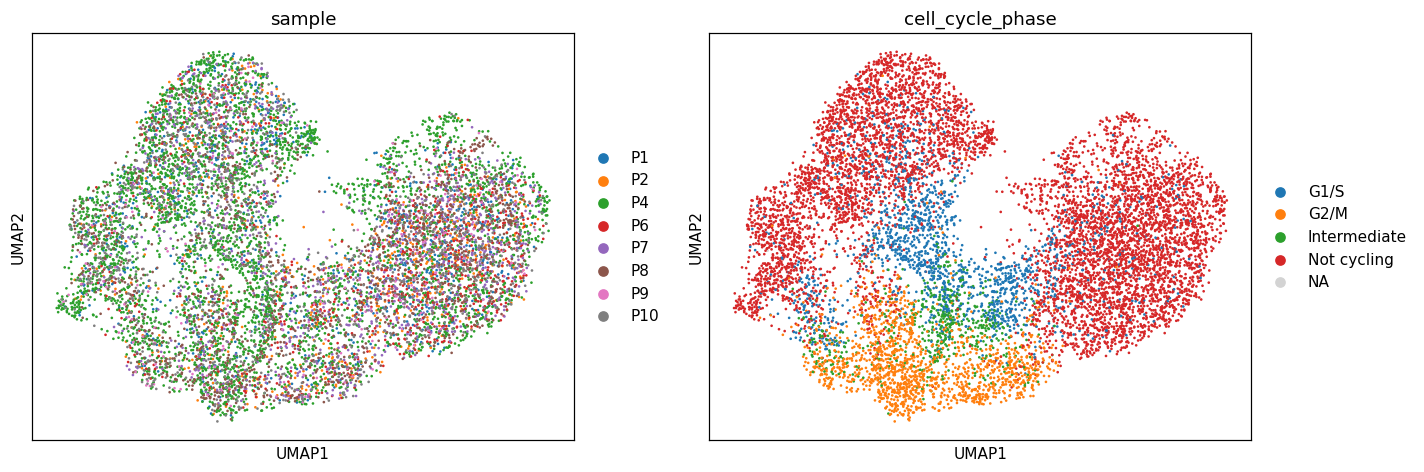

In [10]:
# neighbors -> UMAP (n_pcs=20 from scree; spread=1.3)
sc.pp.neighbors(adata, n_pcs = 20, n_neighbors = 30, use_rep = 'X_pca_harmony')
sc.tl.umap(adata, spread = 1.3)
sc.pl.umap(adata, color = ['sample', 'cell_cycle_phase'], size = 12)

### Continuity + Leiden
The integrated manifold is a single connected kNN component (no detached islands). Leiden confirms there are no sample-private detached clusters to remove.

In [11]:
import scipy.sparse as sp
ncomp, lab = sp.csgraph.connected_components(adata.obsp['distances'], directed = False)
sizes = pd.Series(lab).value_counts()
print('kNN connected components:', ncomp, '| largest fraction: %.3f' % (sizes.iloc[0]/adata.n_obs))

kNN connected components: 1 | largest fraction: 1.000


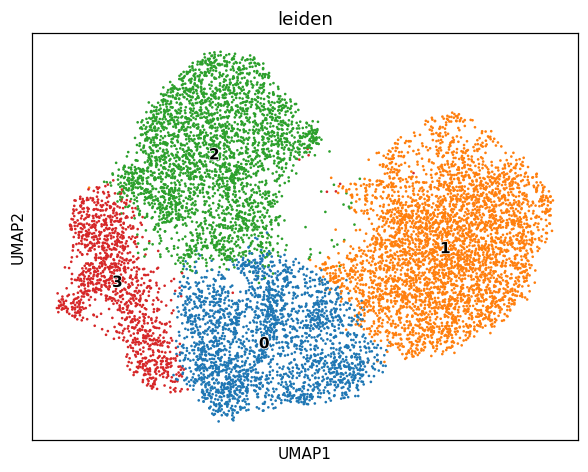

In [12]:
sc.tl.leiden(adata, resolution = 0.3, flavor = 'igraph', n_iterations = 2, directed = False)
sc.pl.umap(adata, color = 'leiden', size = 12, legend_loc = 'on data', legend_fontoutline = True)

### Subtype annotation
Annotation uses **both** data-derived marker expression and the **published Ji et al. 2020 subtypes** (`cell_subtype_level2`): basal (TP63/KRT14/COL17A1), differentiating (KRT1/KRT10/SBSN), TSK leading-edge (MMP10/PTHLH/LAMC2), and cycling (MKI67/TOP2A). Retained as `celltype`.

celltype
Keratinocyte      5688
Tumor_KC_Diff     2345
Tumor_KC_Basal    1393
Tumor_KC_Cyc       785
TSK                320


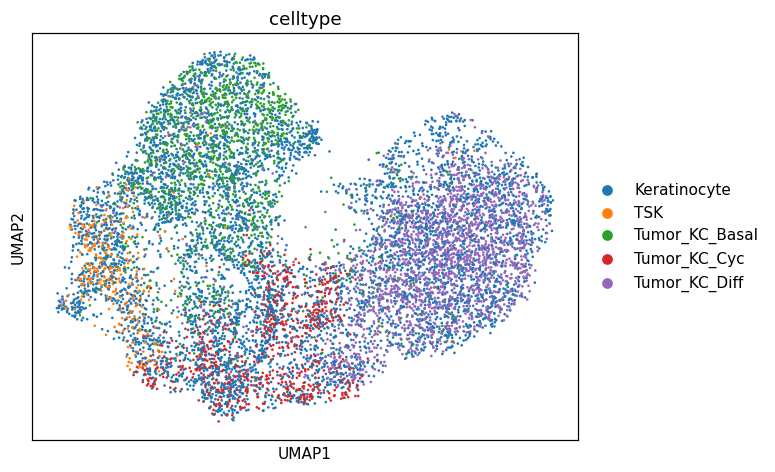

In [13]:
# published subtypes as annotation, confirmed against canonical markers
adata.obs['celltype'] = adata.obs['cell_subtype_level2'].astype('category')
print(adata.obs['celltype'].value_counts().to_string())
sc.pl.umap(adata, color = 'celltype', size = 12)

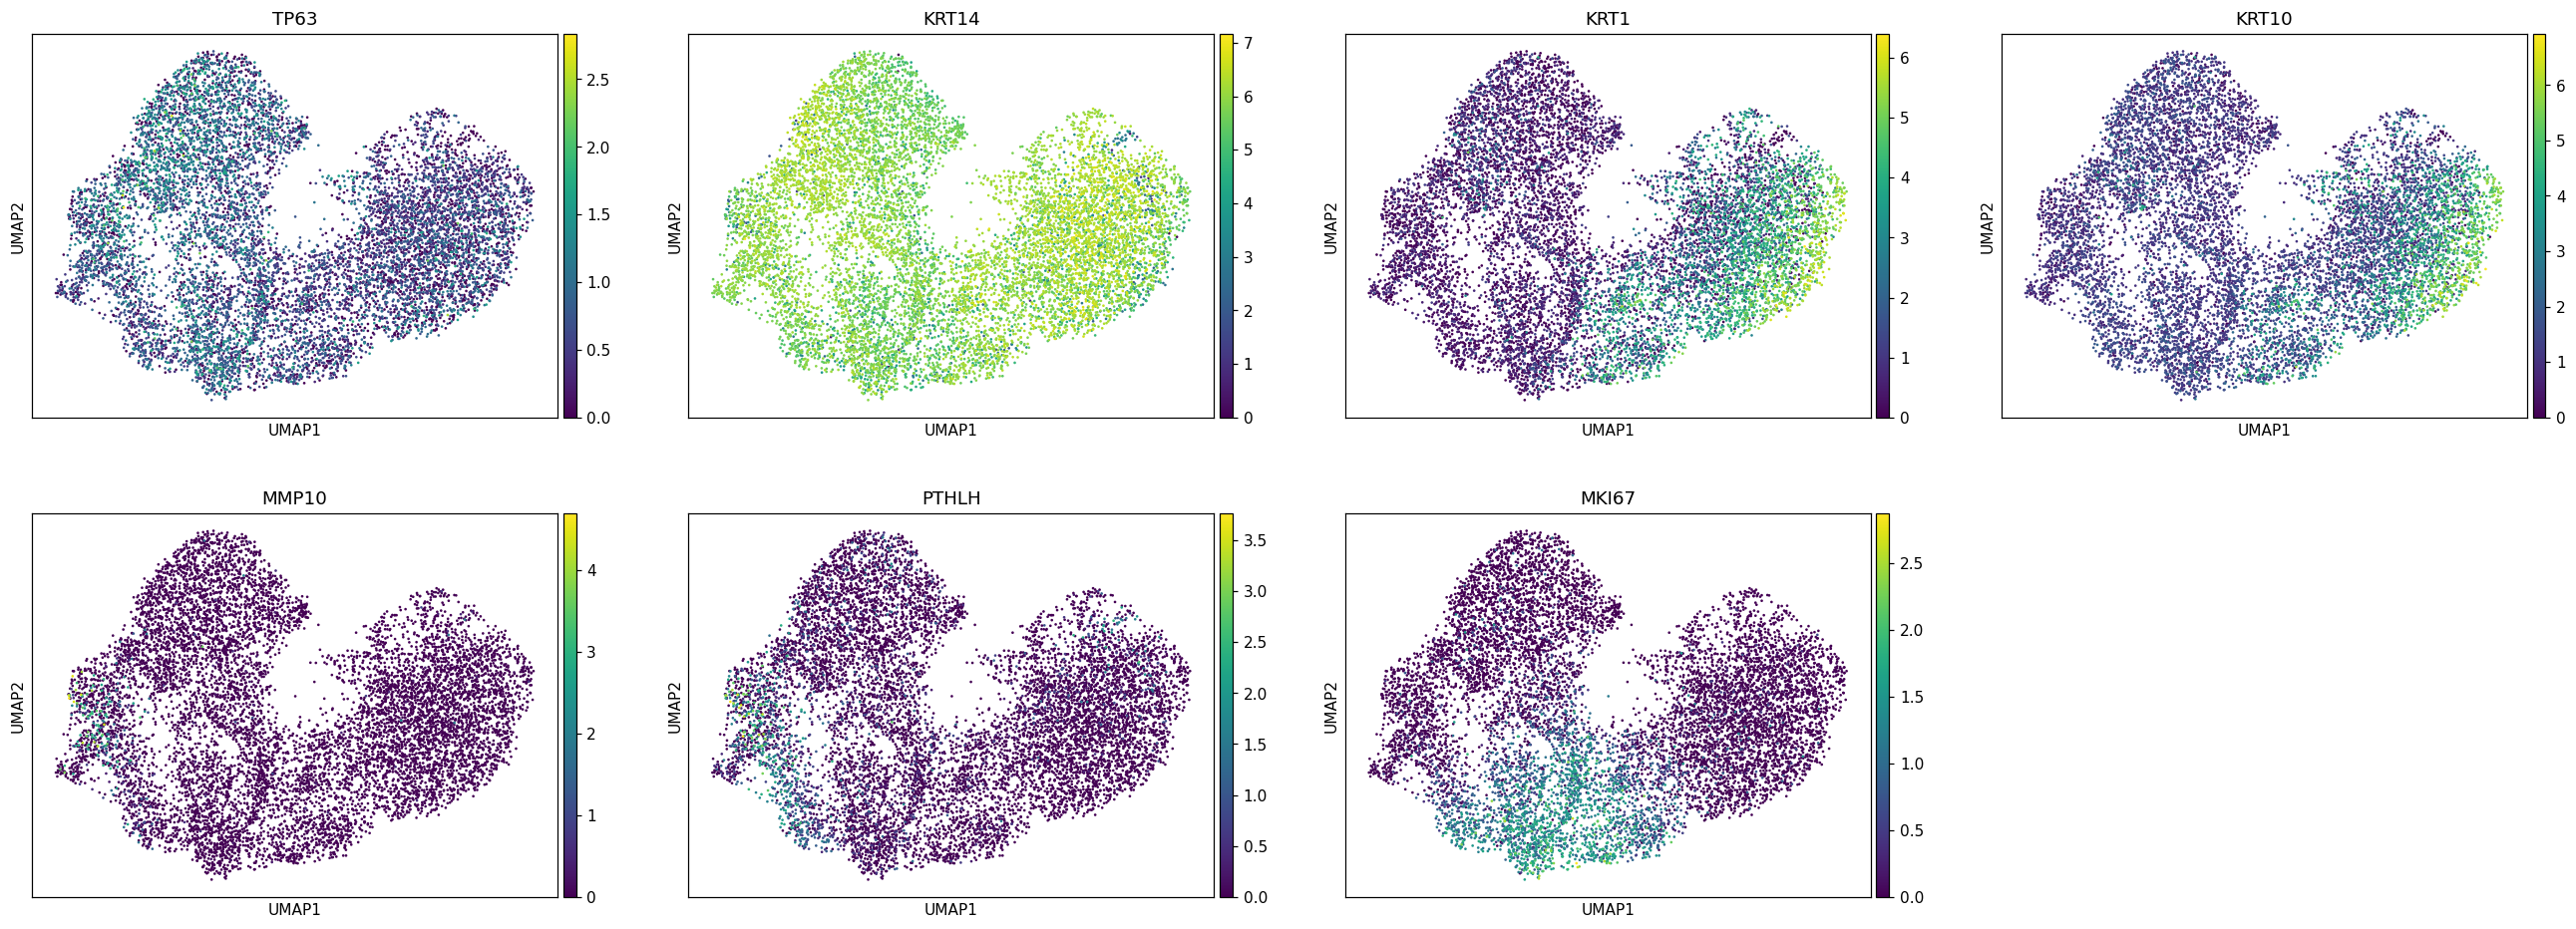

In [14]:
# marker confirmation
mk = [m for m in ['TP63','KRT14','KRT1','KRT10','MMP10','PTHLH','MKI67'] if m in adata.raw.var_names]
sc.pl.umap(adata, color = mk, size = 12, use_raw = True, ncols = 4)

### Save processed data + sample figure

In [15]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))

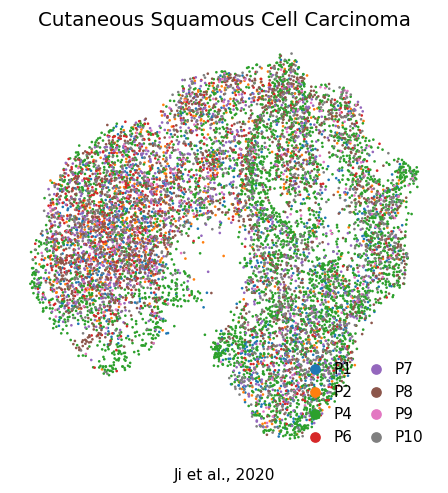

In [16]:
# sample integration figure (reference style: single sample-coloured manifold)
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'sample', size = 12, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol = 2, frameon = False, loc = 'lower right', columnspacing = .5, handletextpad = .25)
ax.set_title('Cutaneous Squamous Cell Carcinoma', size = 13)
ax.text(.5, -.05, 'Ji et al., 2020', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches = 'tight')